#  RNNs Vs Vader , Sentiment analysis, sequectional memory

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import tensorflow as tf

%matplotlib inline

In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
# Set the random seed for reproduccibility
from numpy.random import seed
seed(1)

from tensorflow import random
random.set_seed(2)

In [ ]:
# Load dataset
file_path = Path("data/movie_comments.zip")
df_reviews = pd.read_csv(file_path)
df_reviews.head(10)

,comment,sentiment
0,A question for all you girls out there : If a ...,0
1,It was almost worth sitting through this entir...,0
2,One of the weaker Carry On adventures sees Sid...,0
3,"First of all, I think the below comment is unw...",1
4,This is by far the worst film I have seen in m...,0
5,Well I don't know where to begin. Obviously th...,0
6,When George C. Scott played the title role in ...,0
7,Brilliant! My wife and I joined the sprawling ...,1
8,Kathryn Bigelow and Mark Boal are already prep...,0
9,I'm not sure how I missed this one when it fir...,1


In [ ]:
# Create
X = df_reviews["comment"].values
y = df_reviews["sentiment"].values

In [ ]:
# Create Train data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train)

# Scoring Sentiment using VADER
Vader from nltk

In [ ]:
# import library for VADER
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

In [ ]:
# download/update the Vader lexicon
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [ ]:
analyzer = SentimentIntensityAnalyzer()

In [ ]:
y_vader_pred = []
y_vader_prob = []


In [ ]:
# Scre sentiment for test set uding Vader

for comment in X_test:
  y_vader_prob.append(analyzer.polarity_scores(comment)["pos"])
  sentiment_score = analyzer.polarity_scores(comment)["compound"]
  if sentiment_score >= 0.1:
    y_vader_pred.append(1)
  else:
    y_vader_pred.append(0)

**Normalize option 1**

In [ ]:
# normalize data using MinMaxScaler
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(np.array(y_vader_prob).reshape(-1,1))
y_vader_prob_norm = scaler.transform(np.array(y_vader_prob).reshape(-1,1))
y_vader_prob_norm[:5]


array([[0.16907216],
       [0.74226804],
       [0.12783505],
       [0.24742268],
       [0.04948454]])

**Normalize option 2**

In [ ]:
# Normalize using Comprehension list
normalized = [(x - min(y_vader_prob)) / (max(y_vader_prob) - min(y_vader_prob)) for x in y_vader_prob]
normalized[:5]

[0.16907216494845362,
 0.7422680412371134,
 0.12783505154639174,
 0.24742268041237114,
 0.04948453608247423]

## Scoring etiment using RNN

Encoding data using Tokenizer

In [ ]:
# import Tokenizer
from tensorflow.keras.preprocessing.text import Tokenizer


In [ ]:
# create tokenizer instance
tokenizer = Tokenizer(lower=True)
tokenizer.fit_on_texts(X)

In [ ]:
# Testing encoded data
for token in list(tokenizer.word_index)[:5]:
  print(f"word: '{token}', token: {tokenizer.word_index[token]}")

word: 'the', token: 1
word: 'and', token: 2
word: 'a', token: 3
word: 'of', token: 4
word: 'to', token: 5


In [ ]:
# tansform the text data to numerical sequence
X_seq = tokenizer.texts_to_sequences(X)


In [ ]:
print("**Text comment**")
print({X[0]})

**Text comment**
{'A question for all you girls out there : If a man you`ve never met before accidentally phoned you up on purpose and continued to do so at the most indiscreet moments would you be intrigued by him or so freaked out you`d phone the police ? Yeah that`s what I thought so I couldn`t swallow the idea of Marti Gerrard putting up with the unwarrented attention of Connor Hill<br /><br />***** MILD SPOILERS *****<br /><br />This is a really dumb story . Connor Hill`s wife is murdered and the plot revolves around the question is Connor phoning Marti so he can have an alibi ? But there`s a massive gap in logic here , couldn`t Connor have employed a hit man ? something the prosecution seem to have ignored . And wasn`t there any forensics at the murder scene ? So why does the whole trial rest on Connor phoning Marti at the time of the murder ? Dumb . Dumb . Dumb . And it`s as predictable as it is brainless .<br /><br />My abiding memory of this film is that for someone who made t

In [ ]:
print("#Numerical sequence representation")
print(X_seq[0])

#Numerical sequence representation
[3, 884, 15, 29, 22, 536, 43, 47, 44, 3, 129, 22, 12997, 112, 1829, 156, 2502, 14896, 22, 53, 20, 1284, 2, 3493, 5, 78, 35, 30, 1, 88, 34701, 385, 59, 22, 27, 3691, 31, 87, 39, 35, 8926, 43, 22, 1092, 1693, 1, 565, 1240, 12, 587, 48, 10, 194, 35, 10, 25242, 827, 6192, 1, 323, 4, 30568, 30569, 1484, 53, 16, 1, 52007, 688, 4, 9259, 2186, 7, 7, 3396, 1025, 7, 7, 11, 6, 3, 63, 989, 62, 9259, 2186, 587, 319, 6, 2016, 2, 1, 111, 3050, 184, 1, 884, 6, 9259, 16816, 30568, 35, 26, 67, 25, 32, 12998, 18, 47, 587, 3, 2553, 7180, 8, 2086, 130, 25242, 827, 9259, 25, 5621, 3, 566, 129, 139, 1, 14897, 303, 5, 25, 3692, 2, 27631, 827, 47, 98, 19499, 30, 1, 585, 133, 35, 135, 124, 1, 223, 3096, 357, 20, 9259, 16816, 30568, 30, 1, 55, 4, 1, 585, 989, 989, 989, 2, 9, 587, 14, 724, 14, 9, 6, 6887, 7, 7, 58, 11585, 1751, 4, 11, 19, 6, 12, 15, 291, 34, 90, 1, 3432, 17633, 30568, 30569, 6, 3, 63, 592, 4416, 30570]


**Limit string lenght by pad_sequebces**

In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# set pad size = max size
max_words = 140


X_pad = pad_sequences(X_seq, maxlen=max_words, padding="post")

**Create Traning and Validation**

In [ ]:
X_train_rnn, X_test_rnn, y_train_rnn, y_test_rnn = train_test_split(X_pad, y)

X_train_rnn, X_val_rnn, y_train_rnn, y_val_rnn = train_test_split(X_train_rnn, y_train_rnn)

































## Build and Train RNN model

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense


In [ ]:
# model setup
vocabulary_size = len(tokenizer.word_counts.keys()) + 1
embedding_size = 64

In [ ]:
# Deine LSTM RNN model
model = Sequential()

# Layer 1
model.add(Embedding(vocabulary_size, embedding_size, input_length=max_words))

# Layer 2
model.add(LSTM(units=200))

# Layer 3 Output
model.add(Dense(units=1, activation="sigmoid"))


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
# Compile the model

model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=[
      "accuracy",
      tf.keras.metrics.TruePositives(name="tp"),
      tf.keras.metrics.TrueNegatives(name="tn"),
      tf.keras.metrics.FalsePositives(name="fp"),
      tf.keras.metrics.FalseNegatives(name="fn"),
      tf.keras.metrics.Precision(name="precision"),
      tf.keras.metrics.Recall(name="recall"),
      tf.keras.metrics.AUC(name="auc"),
    ],
)

In [ ]:
# show dummy summery
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

# Training the model

In [ ]:
batch_size = 1000
epochs = 10
model.fit(
    X_train_rnn,
    y_train_rnn,
    validation_data=(X_val_rnn, y_val_rnn),
    epochs=epochs,
    batch_size=batch_size,
    verbose=1,
)

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 79s 5s/step - accuracy: 0.5150 - auc: 0.5303 - fn: 1554.3750 - fp: 2410.0000 - loss: 0.6922 - precision: 0.5157 - recall: 0.5664 - tn: 1708.4375 - tp: 2647.4375 - val_accuracy: 0.5904 - val_auc: 0.7472 - val_fn: 1672.0000 - val_fp: 248.0000 - val_loss: 0.6628 - val_precision: 0.7263 - val_recall: 0.2824 - val_tn: 2110.0000 - val_tp: 658.0000
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 71s 5s/step - accuracy: 0.5472 - auc: 0.6486 - fn: 888.1875 - fp: 2969.6875 - loss: 0.6744 - precision: 0.5617 - recall: 0.7082 - tn: 1148.7500 - tp: 3313.6250 - val_accuracy: 0.5267 - val_auc: 0.6070 - val_fn: 728.0000 - val_fp: 1491.0000 - val_loss: 0.6817 - val_precision: 0.5179 - val_recall: 0.6876 - val_tn: 867.0000 - val_tp: 1602.0000
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 71s 5s/step - accuracy: 0.5509 - auc: 0.6465 - fn: 1163.2500 - fp: 2531.8125 - loss: 0.6716 - precision: 0.5415 - recall: 0.7100 - tn: 1586.6250 - tp: 3038.5625 - val_accuracy: 0.5695 - val_auc: 0.70

In [ ]:
# Predict classes using the testing data
y_rnn_pred = model.predict(X_test_rnn, batch_size=1000)

7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step


**Model Comparison**

In [ ]:
# Accuracy
from sklearn.metrics import accuracy_score

y_rnn_pred_binary = np.round(y_rnn_pred)  # Rounds to the nearest integer (0 or 1)

print("Vader Accuracy: %.2f" % (accuracy_score(y_test, y_vader_pred)))
print("RNN LSTM Accuracy: %.2f" % (accuracy_score(y_test_rnn, y_rnn_pred_binary)))

Vader Accuracy: 0.70
RNN LSTM Accuracy: 0.79


**Confusion Matrix**

In [ ]:
# Import the confusion_matrix method from sklearn
from sklearn.metrics import confusion_matrix

**Confusion Matrix for Vader**

In [ ]:
# Confusion matrtix metrics from Vader
tn_vader, fp_vader, fn_vader, tp_vader = confusion_matrix(y_test, y_vader_pred).ravel()

# Dataframe to display confusion matrix from Vader
cm_vader_df = pd.DataFrame(
    {
        "Positive(1)": [f"TP={tp_vader}", f"FP={fp_vader}"],
        "Negative(0)": [f"FN={fn_vader}", f"TN={tn_vader}"],
    },
    index=["Positive(1)", "Negative(0)"],
)
cm_vader_df.index.name = "Actual"
cm_vader_df.columns.name = "Predicted"
print("Confusion Matrix from Vader")
display(cm_vader_df)

Confusion Matrix from Vader


Predicted,Positive(1),Negative(0)
Actual,,
Positive(1),TP=2610,FN=462
Negative(0),FP=1412,TN=1766


**Confusion Matrix for RNN**

In [ ]:
# Confusion matrtix metrics from the RNN LSTM model
tn_rnn, fp_rnn, fn_rnn, tp_rnn = confusion_matrix(y_test_rnn, y_rnn_pred_binary).ravel()

# Dataframe to display confusion matrix from the RNN LSTM model
cm_rnn_df = pd.DataFrame(
    {
        "Positive(1)": [f"TP={tp_rnn}", f"FP={fp_rnn}"],
        "Negative(0)": [f"FN={fn_rnn}", f"TN={tn_rnn}"],
    },
    index=["Positive(1)", "Negative(0)"],
)
cm_rnn_df.index.name = "Actual"
cm_rnn_df.columns.name = "Predicted"
print("Confusion Matrix from the RNN LSTM Model")
display(cm_rnn_df)

Confusion Matrix from the RNN LSTM Model


Predicted,Positive(1),Negative(0)
Actual,,
Positive(1),TP=2202,FN=878
Negative(0),FP=412,TN=2758


# Classification Report

In [ ]:
# Import the classification_report method from sklearn
from sklearn.metrics import classification_report

In [ ]:
# Display classification report for Vader
print("Classification Report for Vader")
print(classification_report(y_vader_pred, y_test))

Classification Report for Vader
              precision    recall  f1-score   support

           0       0.56      0.79      0.65      2228
           1       0.85      0.65      0.74      4022

    accuracy                           0.70      6250
   macro avg       0.70      0.72      0.69      6250
weighted avg       0.74      0.70      0.71      6250



In [ ]:
# Display classification report for the RNN LSTM Model
print("Classification Report for the RNN LSTM Model")
print(classification_report(y_rnn_pred_binary, y_test_rnn))

Classification Report for the RNN LSTM Model
              precision    recall  f1-score   support

         0.0       0.87      0.76      0.81      3636
         1.0       0.71      0.84      0.77      2614

    accuracy                           0.79      6250
   macro avg       0.79      0.80      0.79      6250
weighted avg       0.81      0.79      0.79      6250



# Plotting Curve

In [ ]:
# Import the roc_curve and auc metrics from sklearn
from sklearn.metrics import roc_curve, auc

**Vader**

In [ ]:
# Data for ROC Curve - VADER
fpr_test_vader, tpr_test_vader, thresholds_test_vader = roc_curve(y_test, y_vader_prob_norm)

In [ ]:
# Data for ROC Curve - VADER
fpr_test_vader, tpr_test_vader, thresholds_test_vader = roc_curve(y_test, y_vader_prob_norm)

In [ ]:
# AUC for VADER
auc_test_vader = auc(fpr_test_vader, tpr_test_vader)
auc_test_vader = round(auc_test_vader, 4)

In [ ]:
# Dataframe to plot ROC Curve for VADER
roc_df_test_vader = pd.DataFrame({"FPR Test": fpr_test_vader, "TPR Test": tpr_test_vader,})

<Axes: title={'center': 'Test ROC Curve - Vader (AUC=0.7386)'}, xlabel='FPR Test'>

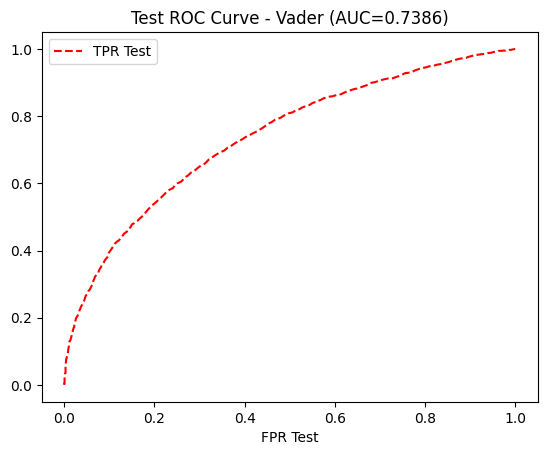

In [ ]:
roc_df_test_vader.plot(
    x="FPR Test",
    y="TPR Test",
    color="red",
    style="--",
    xlim=([-0.05, 1.05]),
    title=f"Test ROC Curve - Vader (AUC={auc_test_vader})",
)

**Plot RNN**

In [ ]:
# Making predictions to feed the roc_curve module
test_predictions_rnn = model.predict(X_test_rnn, batch_size=1000)

7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step


In [ ]:
# Data for ROC Curve - RNN LSTM Model
fpr_test_rnn, tpr_test_rnn, thresholds_test_rnn = roc_curve(y_test_rnn, test_predictions_rnn)

In [ ]:
# AUC for the RNN LSTM Model
auc_test_rnn = auc(fpr_test_rnn, tpr_test_rnn)
auc_test_rnn = round(auc_test_rnn, 4)

In [ ]:
# Dataframe to plot ROC Curve for the RNN LSTM model
roc_df_test_rnn = pd.DataFrame({"FPR Test": fpr_test_rnn, "TPR Test": tpr_test_rnn,})

<Axes: title={'center': 'Test ROC Curve (AUC=0.8832)'}, xlabel='FPR Test'>

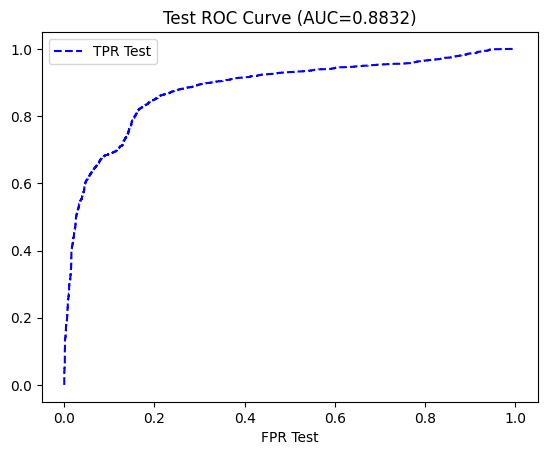

In [ ]:
roc_df_test_rnn.plot(
    x="FPR Test",
    y="TPR Test",
    color="blue",
    style="--",
    xlim=([-0.05, 1.05]),
    title=f"Test ROC Curve (AUC={auc_test_rnn})",
)